<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta10g%C3%B6rev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bulunan resim sayisi: 6
  [0] tsukuba_data/scene1.row3.col1.ppm
  [1] tsukuba_data/scene1.row3.col2.ppm
  [2] tsukuba_data/scene1.row3.col3.ppm
  [3] tsukuba_data/scene1.row3.col4.ppm
  [4] tsukuba_data/scene1.row3.col5.ppm


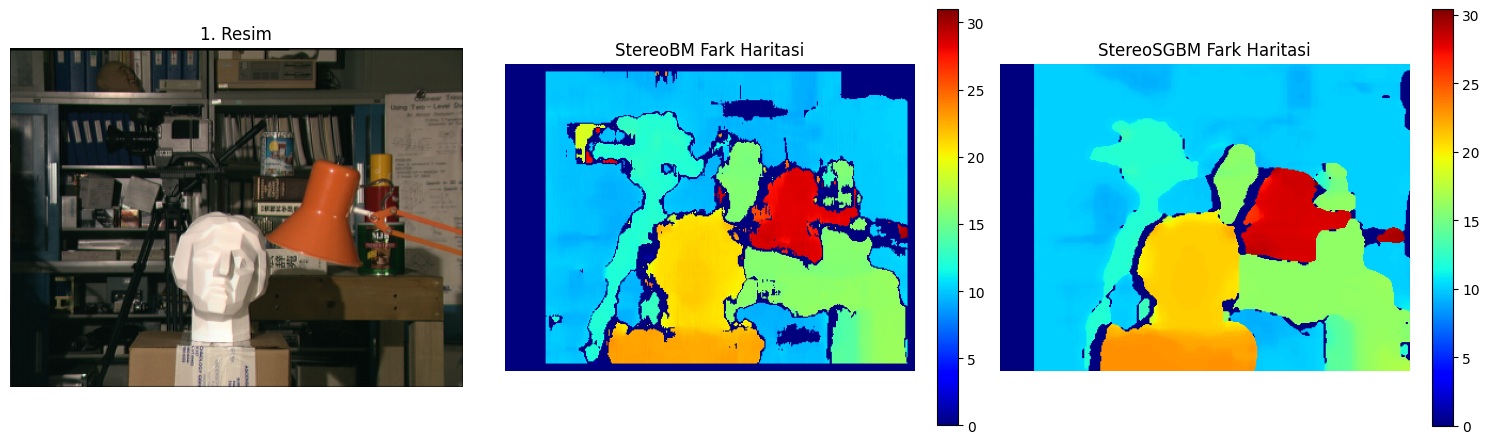

In [ ]:
from pathlib import Path
import urllib.request
import zipfile
import cv2
import matplotlib.pyplot as plt
import numpy as np

url = "https://vision.middlebury.edu/stereo/data/scenes2001/data/tsukuba/tsukuba.zip"
zip_path = Path("tsukuba.zip")
extract_dir = Path("tsukuba_data")

# 1. Indir ve cikart (bozuk dosya kaldiysa yeniden indir)
if zip_path.exists() and not zipfile.is_zipfile(zip_path):
  zip_path.unlink()

if not zip_path.exists():
  req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
  with urllib.request.urlopen(req, timeout=30) as resp, open(
      zip_path, "wb"
  ) as f:
    f.write(resp.read())

with zipfile.ZipFile(zip_path, "r") as zf:
  zf.extractall(extract_dir)

# 2. Goruntuleri bul ve 1. ile 3. resmi al
img_files = sorted([
    p
    for p in extract_dir.rglob("*")
    if p.suffix.lower() in {".ppm", ".pgm", ".png", ".jpg", ".jpeg"}
])
print("Bulunan resim sayisi:", len(img_files))
for idx, p in enumerate(img_files[:5]):
  print(f"  [{idx}] {p}")

assert len(img_files) >= 3, "3'ten az goruntu bulundu."

left_img = cv2.imread(str(img_files[0]))
right_img = cv2.imread(str(img_files[2]))
assert left_img is not None and right_img is not None, "Resimler okunamadi."

left_gray = cv2.cvtColor(left_img, cv2.COLOR_BGR2GRAY)
right_gray = cv2.cvtColor(right_img, cv2.COLOR_BGR2GRAY)

# 3. StereoBM
num_disp = 32  # 16'nin kati olmali
block_size = 15  # Tek sayi olmali

stereo_bm = cv2.StereoBM_create(
    numDisparities=num_disp, blockSize=block_size
)
disp_bm = stereo_bm.compute(left_gray, right_gray).astype(np.float32) / 16.0

# 4. StereoSGBM
stereo_sgbm = cv2.StereoSGBM_create(
    minDisparity=0,
    numDisparities=num_disp,
    blockSize=block_size,
    P1=8 * block_size**2,
    P2=32 * block_size**2,
    disp12MaxDiff=1,
    uniquenessRatio=10,
    speckleWindowSize=100,
    speckleRange=32,
)
disp_sgbm = stereo_sgbm.compute(left_gray, right_gray).astype(np.float32) / 16.0

# 5. Cizdir
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].imshow(cv2.cvtColor(left_img, cv2.COLOR_BGR2RGB))
axes[0].set_title("1. Resim")
axes[0].axis("off")

im1 = axes[1].imshow(np.maximum(disp_bm, 0), cmap="jet")
axes[1].set_title("StereoBM Fark Haritasi")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(np.maximum(disp_sgbm, 0), cmap="jet")
axes[2].set_title("StereoSGBM Fark Haritasi")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()